<a href="https://colab.research.google.com/github/asteriaji/MSSP6070/blob/main/WeeklyModules/Week12/Jiangyu_Ji_PARTICIPATION_ACTIVITY_Week_12_Measure_a_p_value_from_a_t_test_on_a_data_set.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

owner = 'asteriaji'
repository = 'MSSP6070'
repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Repository already exists. Using the existing copy.
Current directory: /content/MSSP6070
Files in repository:
Adding_File_Structure.py
Assignment_Template.ipynb
Assignments/.gitkeep
Assignments/Assignment 1/Corrected_Version_Jiangyu_Ji_MSSP_6070_Assignment_1.ipynb
Assignments/Assignment 1/Jiangyu_Ji_MSSP_6070_Assignment_1_260930.ipynb
Assignments/Assignment 2/1
Assignments/Assignment 2/Jiangyu_Ji_Assignment_2.ipynb
WeeklyModules/.gitkeep
WeeklyModules/Week01/.gitkeep
WeeklyModules/Week01/1_introducing_matplotlib_(1).ipynb
WeeklyModules/Week01/Week1_Jiangyu_Ji_Participation_Activity_Exercises_260828.ipynb
WeeklyModules/Week01/stats_viz (1).py
WeeklyModules/Week02/.gitkeep
WeeklyModules/Week02/Week2_Jiangyu_Ji_Participation_Activity_260907__(2).ipynb
WeeklyModules/Week02/Week_2_Data_Stuctures.ipynb
WeeklyModules/Week03/.gitkeep
WeeklyModules/Week03/Week_3_Jiangyu_Ji_PARTICIPATION_ACTIVITY_(3)_(2).ipynb
WeeklyModules/Week04/.gitkeep
WeeklyModules/Week04/Jiangyu_Ji_Assignment_PARTICIPATION

In [48]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = repo_path /'data'/'Student Performance Data (2).csv'

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Data file not found: {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH,encoding="latin1")

print("Data loaded successfully!")
print("Data shape:", df.shape)
display(df.head())

Data loaded successfully!
Data shape: (1000, 10)


,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium
1,female,group C,some college,standard,69,90,88,247,completed,high
2,female,group B,master's degree,standard,90,95,93,278,none,high
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low
4,male,group C,some college,standard,76,78,75,229,none,high


In [49]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
# seaborn is a package for the visualization of statistical data
import seaborn as sns
sns.set(style='ticks')

pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [50]:
# Is there a statistical difference between males who took the preparation
# exam and others?

# H0: There is no significant difference between males who took the preparation
# exam and others

In [51]:
df["total score"].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
# The average total score is 203.31, with a standard deviation of 42.77.

,total score
count,1000.00
mean,203.31
median,205.00
std,42.77
min,27.00
max,300.00


In [52]:
df['group'] = np.where(
    (df['gender'] == 'male') &
    (df['test preparation course'] == 'completed'),
    'Male_Completed',
    'Others')

In [53]:
df.groupby('group')['total score'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max'])

# The average total score for male students who took the preparation exam
# is 212.34, with a standard deviation of 39.60.

# Others: males who didn't take the preparation exam ; all females
# The average total score for others is 201.41, with a standard deviation of 43.19.

,count,mean,median,std,min,max
group,,,,,,
Male_Completed,174,212.34,213.00,39.60,119,300
Others,826,201.41,204.00,43.19,27,300


In [54]:
# Group 1: Male students who completed the preparation course
group1 = df[
    (df['gender'] == 'male') &
    (df['test preparation course'] == 'completed')
]['total score'].dropna()

# Group 2: Everyone else
group2 = df[
    ~((df['gender'] == 'male') &
      (df['test preparation course'] == 'completed'))
]['total score'].dropna()

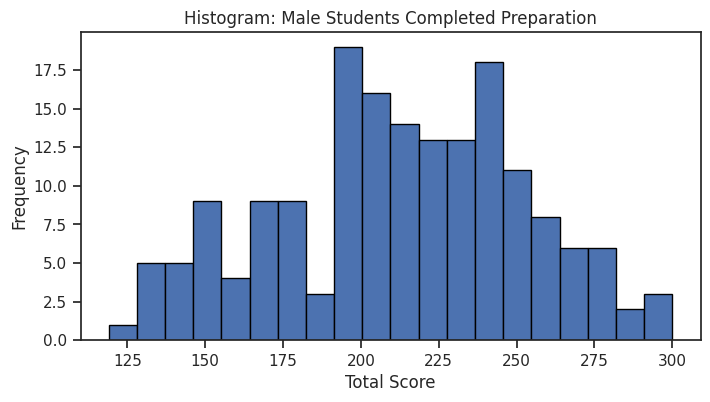

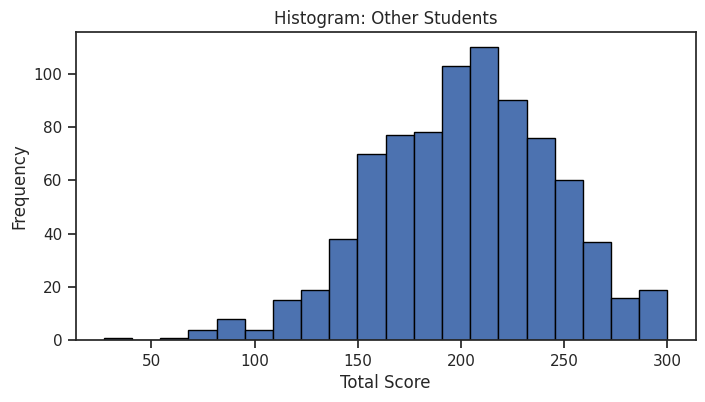

In [55]:
# Histogram for Group 1: Male Completed
plt.figure(figsize=(8, 4))
plt.hist(group1, bins=20, edgecolor='black')
plt.title('Histogram: Male Students Completed Preparation')
plt.xlabel('Total Score')
plt.ylabel('Frequency')
plt.show()

# Histogram for Group 2: Others
plt.figure(figsize=(8, 4))
plt.hist(group2, bins=20, edgecolor='black')
plt.title('Histogram: Other Students')
plt.xlabel('Total Score')
plt.ylabel('Frequency')
plt.show()

# Both groups show variation in total scores, with the first group generally having
# higher scores. The distributions do not appear perfectly symmetric, suggesting
# that there may be some departures from normality.
# Therefore, additional normality assessments, including Q-Q plots and the
# Shapiro-Wilk test, are conducted.

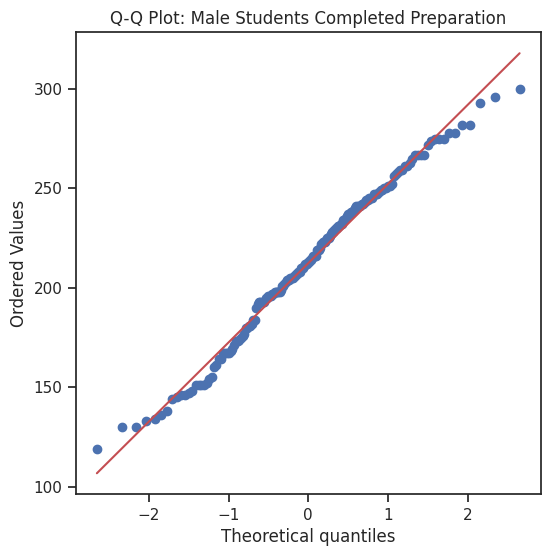

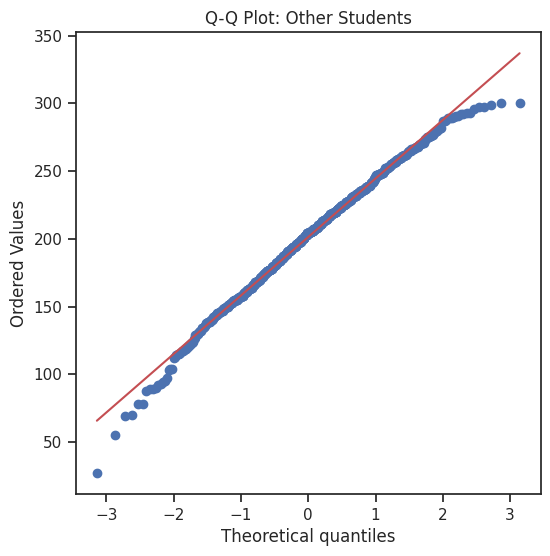

In [56]:
# Q-Q Plot for Group 1
plt.figure(figsize=(6, 6))
stats.probplot(group1, dist='norm', plot=plt)
plt.title('Q-Q Plot: Male Students Completed Preparation')
plt.show()

# Q-Q Plot for Group 2
plt.figure(figsize=(6, 6))
stats.probplot(group2, dist='norm', plot=plt)
plt.title('Q-Q Plot: Other Students')
plt.show()

# Both groups' Q-Q plots generally follow the reference line,
# although some deviations may exist at the tails.

In [57]:
# Calculate Standard Errors
SE1 = stats.sem(group1)
SE2 = stats.sem(group2)

print('SE of Male Completed:', SE1)
print('SE of Others:', SE2)

# The standard error for male students who completed the preparation course is 3.00,
# while the standard error for the other students is 1.50.
# The second group's standard error is smaller, indicating that its sample mean is
# estimated with greater precision.

SE of Male Completed: 3.0019223479350594
SE of Others: 1.5028818600291072


In [58]:
# Shapiro-Wilk Test
stat1, p1 = stats.shapiro(group1)
stat2, p2 = stats.shapiro(group2)

print('Shapiro p-value (Group 1):', p1)
print('Shapiro p-value (Group 2):', p2)

# For the first group (male students who completed the preparation course),
# the p-value is 0.1041, which is greater than 0.05. Therefore, we fail to reject
# the null hypothesis, meaning there is insufficient evidence to conclude that the
# scores deviate from a normal distribution.
# For the second group (all other students), the p-value is 0.0007, which is
# smaller than 0.05. Therefore, we reject the null hypothesis, indicating evidence
# that the scores are not normally distributed.
# Overall, the two groups do not both satisfy the normality assumption based on
# the Shapiro-Wilk test. However, given the relatively large sample sizes,
# Welch's t-test can still be considered, as it is generally robust to moderate
# departures from normality.

Shapiro p-value (Group 1): 0.10414127310783877
Shapiro p-value (Group 2): 0.0007198119965424672


In [59]:
# Levene's Test
stat, p_value = stats.levene(group1, group2)
print('Levene p-value:', p_value)

# The p-value of Levene's test is 0.3320, which is greater than the significance
# level of 0.05.
# Therefore, we fail to reject the null hypothesis that the two groups have equal
# variances. There is insufficient evidence to conclude that the variances of the
# two groups are significantly different.

Levene p-value: 0.332027069560889


In [60]:
# Independent Samples Welch's t-test
t_stat, p_value = stats.ttest_ind(
    group1, group2, equal_var=False
)

print('t-statistic:', t_stat)
print('p-value:', p_value)

if p_value < 0.05:
    print('There is a significant difference between the two groups.')
else:
    print('There is no significant difference between the two groups.')

# The Welch's independent samples t-test produces a t-statistic of 3.2575 and
# a p-value of 0.00127.
# Since the p-value is smaller than 0.05, we reject the null hypothesis.
# This indicates a statistically significant difference in mean total scores
# between male students who completed the test preparation course and all other
# students.

t-statistic: 3.257451981231156
p-value: 0.0012695902226222658
There is a significant difference between the two groups.
